In [1]:
import os
from dotenv import load_dotenv
from langchain_community.vectorstores import FAISS
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_community.document_loaders import WebBaseLoader
from langchain_classic.schema import Document
from typing import List
from pydantic import BaseModel
from langgraph.graph import StateGraph,END
from langchain_text_splitters import RecursiveCharacterTextSplitter

USER_AGENT environment variable not set, consider setting it to identify your requests.


In [2]:
!ollama pull deepseek-v2

pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest 
pulling d8d69f2a1bfa: 100% ▕██████████████████▏ 8.9 GB                         
pulling b321cd7de6c7: 100% ▕██████████████████▏  111 B                         
pulling 4bb71764481f: 100% ▕██████████████████▏  13 KB                         
pulling 19f2fb9e8bc6: 100% ▕██████████████████▏   32 B                         
pulling 2b2c35718a16: 100% ▕██████████████████▏  494 B                         
verifying sha256 digest 
writing manifest 
removing unused layers ⠋ pulling manifest 
pulling d8d69f2a1bfa: 100% ▕██████████████████▏ 8.9 GB                         
pulling b321cd7de6c7: 100% ▕██████████████████▏  111 B                         
pulling 4bb71764481f: 100% ▕██████████████████▏  13 KB                

In [4]:
from langchain.chat_models import init_chat_model
load_dotenv(override=True)
os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")
os.environ["OLLAMA_API_KEY"]=os.getenv("OLLAMA_API_KEY")

llm=init_chat_model("deepseek-v2",
model_provider="ollama",
temperature=0.1)
llm.invoke("Hello").content

' Hello! How can I assist you today?'

In [5]:
urls=[
    "https://lilianweng.github.io/posts/2023-06-23-agent/",
    "https://lilianweng.github.io/posts/2024-04-12-diffusion-video/"
]
docs=[]
for url in urls:
    docs.extend(WebBaseLoader(url).load())
splitter=RecursiveCharacterTextSplitter(chunk_size=1000,chunk_overlap=100)
chunks=splitter.split_documents(docs)
embedding= HuggingFaceEmbeddings()
vs=FAISS.from_documents(chunks,embedding)
retriever=vs.as_retriever()


d:\Agentic\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 376.13it/s]


In [14]:

#State Schema:
class RAGState(BaseModel):
    question: str
    sub_questions: List[str] = []
    retrieved_docs: List[Document] = []
    answer: str = ""
    

In [15]:
## Query Planner:
def plan_query(state: RAGState) -> RAGState:
   
    prompt = f"""
Break the following complex question into 2-3 sub-questions:

Question: {state.question}

Sub-questions:
"""
    result = llm.invoke(prompt)
    sub_questions = [line.strip("- ").strip() for line in result.content.strip().split("\n") if line.strip()]
    return RAGState(question=state.question, sub_questions=sub_questions)

## b. Retrieve documents for each sub-question
def retrieve_for_each(state: RAGState) -> RAGState:
    all_docs = []
    for sub in state.sub_questions:
        docs = retriever.invoke(sub)
        all_docs.extend(docs)
    return RAGState(question=state.question, sub_questions=state.sub_questions, retrieved_docs=all_docs)

## c. Generate final answer
def generate_final_answer(state: RAGState) -> RAGState:
    context = "\n\n".join([doc.page_content for doc in state.retrieved_docs])
    prompt = f"""
Use the context below to answer the question.

Context:
{context}

Question: {state.question}
"""
    
    answer = llm.invoke(prompt).content
    return RAGState(question=state.question, sub_questions=state.sub_questions, retrieved_docs=state.retrieved_docs, answer=answer)

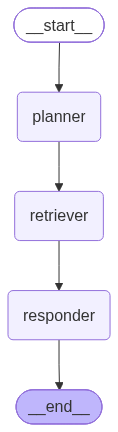

In [16]:
builder = StateGraph(RAGState)

builder.add_node("planner", plan_query)
builder.add_node("retriever", retrieve_for_each)
builder.add_node("responder", generate_final_answer)

builder.set_entry_point("planner")
builder.add_edge("planner", "retriever")
builder.add_edge("retriever", "responder")
builder.add_edge("responder", END)

graph = builder.compile()
graph

In [17]:
if __name__ == "__main__":
    user_query = "Explain how agent loops work and what are the challenges in diffusion video generation?"
    initial_state = RAGState(question=user_query)
    final_state = graph.invoke(initial_state)
    print(final_state)

    print("\n🔍 Sub-questions:")
    for q in final_state['sub_questions']:
        print("-", q)

    print("\n✅ Final Answer:\n", final_state['answer'])

{'question': 'Explain how agent loops work and what are the challenges in diffusion video generation?', 'sub_questions': ['1. How do agent loops function in video generation?', '2. What are the main challenges faced in diffusion video generation?'], 'retrieved_docs': [Document(id='6bbfb3b9-914d-4be7-bef1-cbd7a499e936', metadata={'source': 'https://lilianweng.github.io/posts/2024-04-12-diffusion-video/', 'title': "Diffusion Models for Video Generation | Lil'Log", 'description': 'Diffusion models have demonstrated strong results on image synthesis in past years. Now the research community has started working on a harder task—using it for video generation. The task itself is a superset of the image case, since an image is a video of 1 frame, and it is much more challenging because:\n\nIt has extra requirements on temporal consistency across frames in time, which naturally demands more world knowledge to be encoded into the model.\nIn comparison to text or images, it is more difficult to c